In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reaidng the data 

In [109]:
df=pd.read_csv("D:\Courses\ML for data analysis (NTI)\Exercise\DT\Project Apartments Prices Dataset\Apartments Prices Dataset(Target column price).csv")
df.head()

<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
<>:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
C:\Users\abdoa\AppData\Local\Temp\ipykernel_11348\418571653.py:1: SyntaxWarning: "\C" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\C"? A raw string is also an option.
  df=pd.read_csv("D:\Courses\ML for data analysis (NTI)\Exercise\DT\Project Apartments Prices Dataset\Apartments Prices Dataset(Target column price).csv")


,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


# EDA

In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   price           5572 non-null   str  
 1   area_sqm        5545 non-null   str  
 2   rooms           5550 non-null   str  
 3   bathrooms       5480 non-null   str  
 4   floor_level     5578 non-null   str  
 5   year_built      5578 non-null   int64
 6   seller_type     5387 non-null   str  
 7   view            5556 non-null   str  
 8   price_per_sqm   5534 non-null   str  
 9   payment_method  5566 non-null   str  
 10  finishing_type  5578 non-null   str  
dtypes: int64(1), str(10)
memory usage: 961.6 KB


In [111]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [112]:
df.isnull().sum().sort_values(ascending=False)

seller_type       191
bathrooms          98
price_per_sqm      44
area_sqm           33
rooms              28
view               22
payment_method     12
price               6
floor_level         0
year_built          0
finishing_type      0
dtype: int64

In [113]:
df.duplicated().sum()

np.int64(1298)

In [114]:
df.shape

(5578, 11)

In [115]:
df.drop_duplicates(inplace=True)

In [116]:
df.reset_index(drop=True,inplace=True)

In [117]:
df.duplicated().sum()

np.int64(0)

# Feature Engineering

In [118]:
df.drop(['price_per_sqm'],axis=1, inplace=True)
df.reset_index(drop=True,inplace=True)

In [119]:
df['seller_type'].value_counts()

seller_type
Broker                  3569
Developer                333
Private Owner            177
Compound Developer        20
Cash                       5
Cash or Installments       3
Installments               1
Name: count, dtype: int64

In [120]:
df['seller_type']=df['seller_type'].replace("Cash", np.nan)

In [121]:
df['seller_type']=df['seller_type'].replace("Cash or Installments", np.nan)

In [122]:
df['seller_type']=df['seller_type'].replace("Installments", np.nan)

In [123]:
df['seller_type'].value_counts()

seller_type
Broker                3569
Developer              333
Private Owner          177
Compound Developer      20
Name: count, dtype: int64

In [124]:
df["area_sqm"]=df["area_sqm"].str.replace("m²", " ").astype(float)

In [125]:
df['price'] = df['price'].str.replace(' EGP', '').str.replace(',', '').astype(float)

In [126]:
df['bathrooms'] = df['bathrooms'].str.replace(' bathroom', '', regex=False).astype(float)

In [127]:
df['rooms']=df['rooms'].str.replace(' rooms','', regex=False).astype(float)

In [128]:
df['floor_level'] = pd.to_numeric(df['floor_level'], errors='coerce')

# Missing values and duplication

In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           4274 non-null   float64
 1   area_sqm        4247 non-null   float64
 2   rooms           4252 non-null   float64
 3   bathrooms       4183 non-null   float64
 4   floor_level     4128 non-null   float64
 5   year_built      4280 non-null   int64  
 6   seller_type     4099 non-null   str    
 7   view            4259 non-null   str    
 8   payment_method  4268 non-null   str    
 9   finishing_type  4280 non-null   str    
dtypes: float64(5), int64(1), str(4)
memory usage: 486.4 KB


In [130]:
df.isnull().sum().sort_values(ascending=False)

seller_type       181
floor_level       152
bathrooms          97
area_sqm           33
rooms              28
view               21
payment_method     12
price               6
year_built          0
finishing_type      0
dtype: int64

<Axes: ylabel='Frequency'>

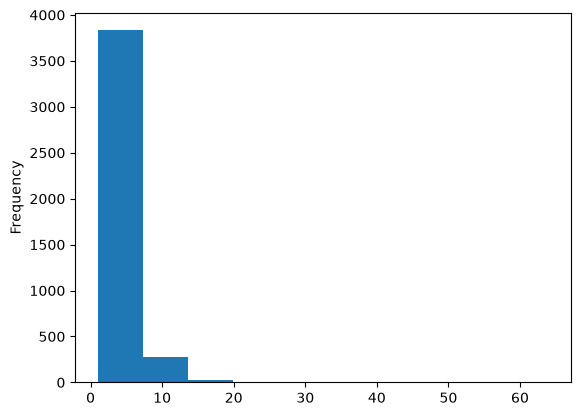

In [131]:
df['floor_level'].plot(kind='hist')

In [132]:
df['floor_level'].skew()

np.float64(4.552237794148692)

<Axes: ylabel='Frequency'>

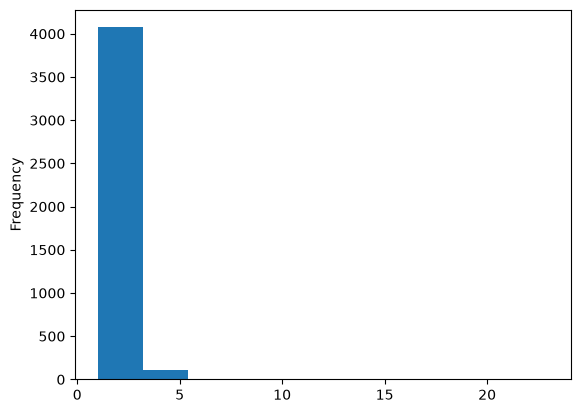

In [133]:
df['bathrooms'].plot(kind='hist')

In [134]:
df['bathrooms'].skew()

np.float64(4.840610648135993)

In [135]:
df['area_sqm'].skew()

np.float64(0.7325684238767584)

<Axes: ylabel='Frequency'>

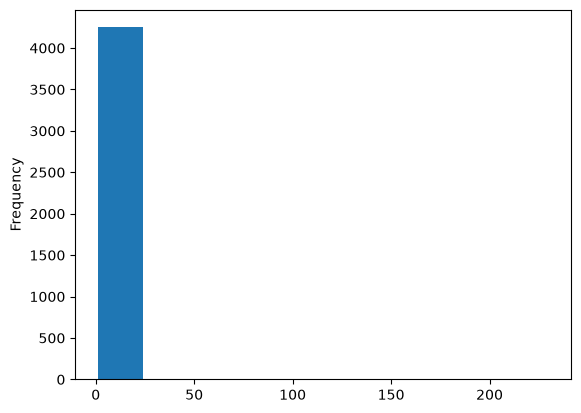

In [136]:
df['rooms'].plot(kind='hist')

In [137]:
df['rooms'].skew()

np.float64(47.843133437150385)

<Axes: ylabel='Frequency'>

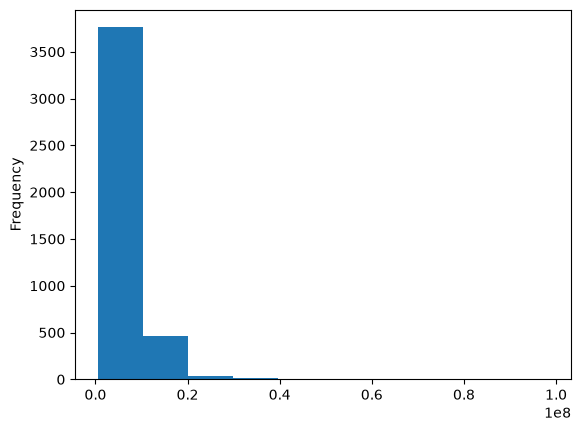

In [138]:
df['price'].plot(kind='hist')

In [139]:
df['price'].skew()

np.float64(5.754595146637905)

In [140]:
col=['floor_level','bathrooms','area_sqm','rooms','price']

In [141]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='median')
for i in col:
    df[[i]]=imputer.fit_transform(df[[i]])

In [142]:
obj_col=['seller_type','view','payment_method']

In [143]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for z in obj_col:
    df[[z]]=imputer.fit_transform(df[[z]])

In [144]:
df.isnull().sum().sort_values(ascending=False)

price             0
area_sqm          0
rooms             0
bathrooms         0
floor_level       0
year_built        0
seller_type       0
view              0
payment_method    0
finishing_type    0
dtype: int64

In [145]:
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,payment_method,finishing_type
0,2163000.0,120.0,2.0,3.0,3.0,2025,Developer,Main Street,Installments,Semi Finished
1,3250000.0,162.0,3.0,2.0,6.0,2024,Developer,Main Street,Cash or Installments,Semi Finished
2,2650000.0,122.0,3.0,1.0,4.0,2024,Developer,Main Street,Cash or Installments,Semi Finished
3,12720000.0,212.0,4.0,3.0,13.0,2027,Broker,Club,Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2.0,1.0,6.0,2025,Developer,Lake,Cash or Installments,Super Lux


In [146]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           4280 non-null   float64
 1   area_sqm        4280 non-null   float64
 2   rooms           4280 non-null   float64
 3   bathrooms       4280 non-null   float64
 4   floor_level     4280 non-null   float64
 5   year_built      4280 non-null   int64  
 6   seller_type     4280 non-null   str    
 7   view            4280 non-null   str    
 8   payment_method  4280 non-null   str    
 9   finishing_type  4280 non-null   str    
dtypes: float64(5), int64(1), str(4)
memory usage: 486.1 KB


# Visualization


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
 [Text(0, 0, '1.0'),
  Text(1, 0, '2.0'),
  Text(2, 0, '3.0'),
  Text(3, 0, '4.0'),
  Text(4, 0, '5.0'),
  Text(5, 0, '7.0'),
  Text(6, 0, '10.0'),
  Text(7, 0, '13.0'),
  Text(8, 0, '33.0'),
  Text(9, 0, '123.0'),
  Text(10, 0, '230.0')])

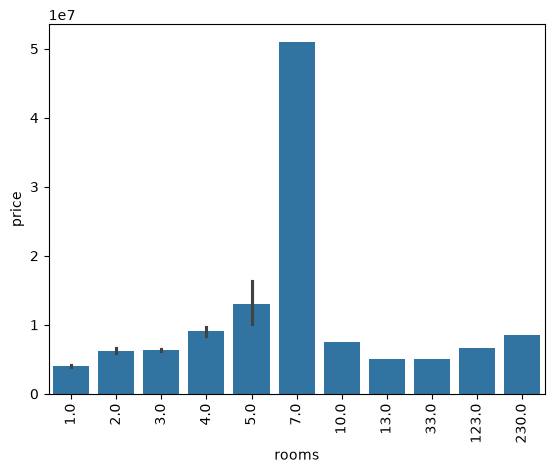

In [147]:
sns.barplot(data=df,x='rooms',y='price')
plt.xticks(rotation=90)

<Axes: xlabel='area_sqm', ylabel='price'>

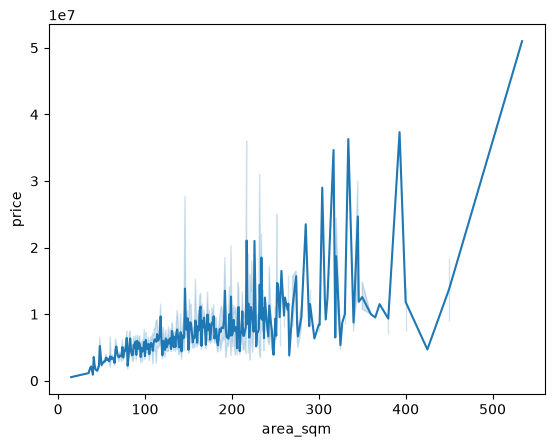

In [148]:
sns.lineplot(data=df,x='area_sqm',y='price')

(array([1900., 1920., 1940., 1960., 1980., 2000., 2020., 2040., 2060.]),
 [Text(1900.0, 0, '1900'),
  Text(1920.0, 0, '1920'),
  Text(1940.0, 0, '1940'),
  Text(1960.0, 0, '1960'),
  Text(1980.0, 0, '1980'),
  Text(2000.0, 0, '2000'),
  Text(2020.0, 0, '2020'),
  Text(2040.0, 0, '2040'),
  Text(2060.0, 0, '2060')])

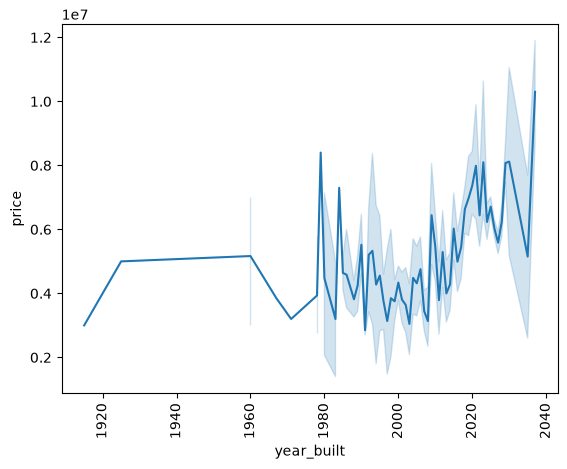

In [149]:
sns.lineplot(data=df,x='year_built',y='price')
plt.xticks(rotation=90)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, 'Main Street'),
  Text(1, 0, 'Club'),
  Text(2, 0, 'Lake'),
  Text(3, 0, 'Side Street'),
  Text(4, 0, 'Other'),
  Text(5, 0, 'Garden'),
  Text(6, 0, 'Sea View'),
  Text(7, 0, 'Pool'),
  Text(8, 0, 'Plaza'),
  Text(9, 0, 'Corner'),
  Text(10, 0, 'Nile View'),
  Text(11, 0, 'Back'),
  Text(12, 0, 'Golf Course')])

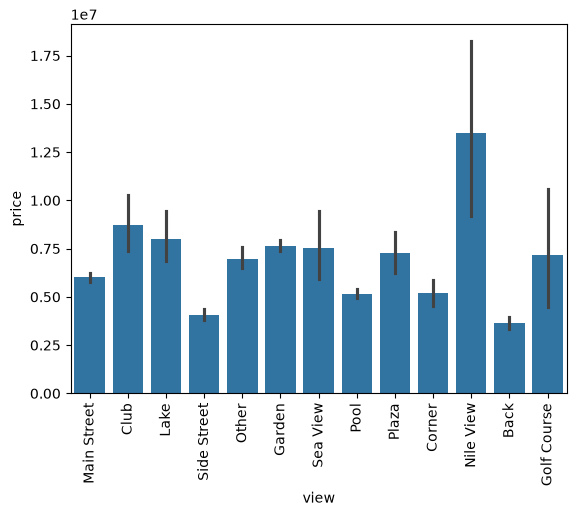

In [150]:
sns.barplot(data=df,x='view',y='price')
plt.xticks(rotation=90)

[Text(0, 0.5, 'price'),
 Text(0, 1.5, 'area_sqm'),
 Text(0, 2.5, 'rooms'),
 Text(0, 3.5, 'bathrooms'),
 Text(0, 4.5, 'floor_level'),
 Text(0, 5.5, 'year_built')]

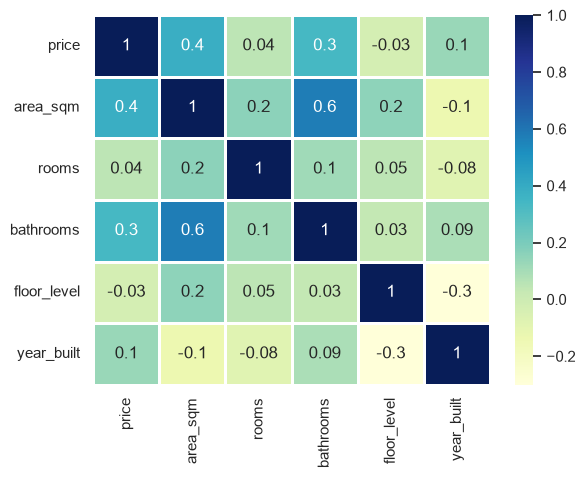

In [151]:
df_corr= df.select_dtypes(include='number')

sns.set(style='whitegrid')
plt.Figure(figsize=(15,6))

linewidths = 1

ax = sns.heatmap(df_corr.corr(), annot=True, fmt="0.1g", cmap="YlGnBu",linewidths=linewidths)


ax.set_xticklabels(df_corr.columns)  
ax.set_yticklabels(df_corr.columns)  


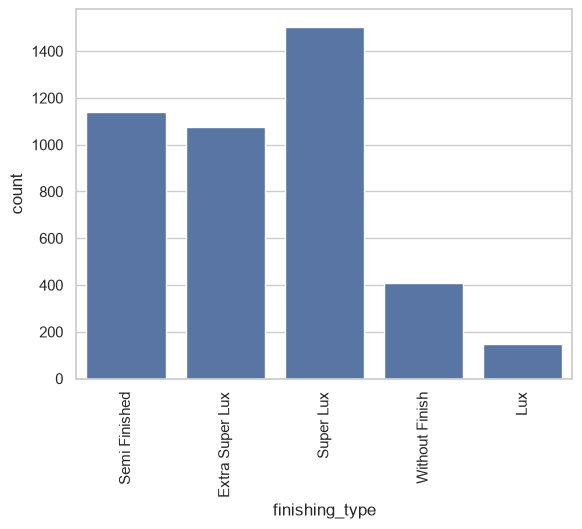

In [152]:
sns.countplot(x=df["finishing_type"])
plt.xticks(rotation=90)
plt.show()

# Preprocessing

In [153]:
#from sklearn.preprocessing import OneHotEncoder, LabelEncoder


In [154]:
"""
ohe=OneHotEncoder(sparse_output=False,
                  handle_unknown='ignore',
                  drop='first'
).set_output(transform='pandas')
"""

"\nohe=OneHotEncoder(sparse_output=False,\n                  handle_unknown='ignore',\n                  drop='first'\n).set_output(transform='pandas')\n"

In [155]:
#df.head()

In [156]:
#col=['seller_type','payment_method']

In [157]:
#or CO in col:
 #   Temp=ohe.fit_transform(df[[CO]])
#    df=pd.concat([df,Temp],axis=1)

In [158]:
#df.drop(['seller_type','payment_method'],axis=1,inplace=True)

In [159]:
#df.reset_index(drop=True,inplace=True)

In [160]:
#le=LabelEncoder()

In [161]:
#C=['view','finishing_type']

In [162]:
#for i in C:
 #   df[i]=le.fit_transform(df[[i]])

In [163]:
#df.head()

<Axes: ylabel='rooms'>

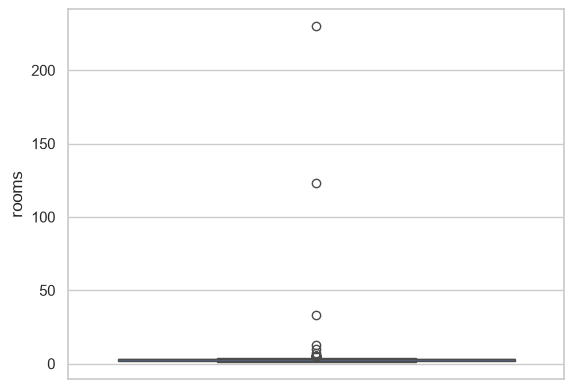

In [164]:
sns.boxplot(df['rooms'])

<Axes: ylabel='bathrooms'>

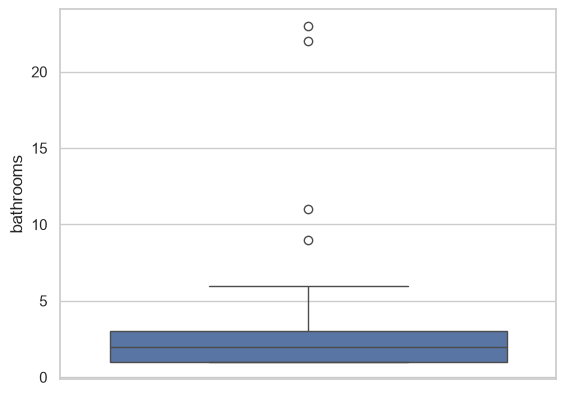

In [165]:
sns.boxplot(df['bathrooms'])

<Axes: ylabel='year_built'>

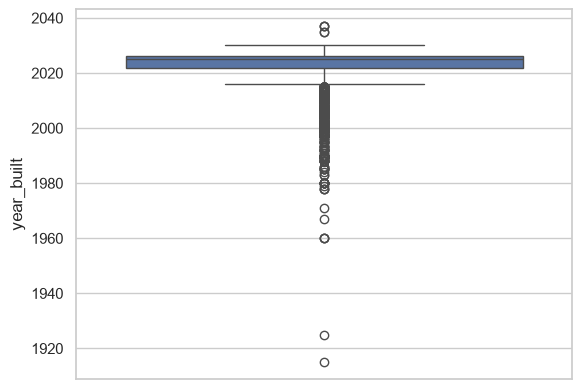

In [166]:
sns.boxplot(df['year_built'])

In [167]:
"""
def remove_outliers_iqr(data, column_name="value"):
    
    Removes outliers using the IQR method.
    Returns filtered DataFrame.
    
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name=['year_built','bathrooms','rooms'])

print(df.shape,cleaned_df.shape)
"""

'\ndef remove_outliers_iqr(data, column_name="value"):\n\n    Removes outliers using the IQR method.\n    Returns filtered DataFrame.\n\n    Q1 = df[column_name].quantile(0.25)\n    Q3 = df[column_name].quantile(0.75)\n    IQR = Q3 - Q1\n    lower = Q1 - 1.5 * IQR\n    upper = Q3 + 1.5 * IQR\n    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]\ncleaned_df = remove_outliers_iqr(df, column_name=[\'year_built\',\'bathrooms\',\'rooms\'])\n\nprint(df.shape,cleaned_df.shape)\n'

In [168]:
#X=df.drop(['price'],axis=1)
#y=df['price']

In [169]:
#rom sklearn.model_selection import train_test_split
#X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,stratify=None,test_size=0.20)

In [170]:
#X_train.head()

In [171]:
#from sklearn.preprocessing import StandardScaler

In [172]:
#scal=StandardScaler()

In [173]:
"""
X_train[['year_built','price_per_sqm']] = scal.fit_transform(
    X_train[['year_built','price_per_sqm']]
)

X_test[['year_built','price_per_sqm']] = scal.transform(
    X_test[['year_built','price_per_sqm']]
)
"""

"\nX_train[['year_built','price_per_sqm']] = scal.fit_transform(\n    X_train[['year_built','price_per_sqm']]\n)\n\nX_test[['year_built','price_per_sqm']] = scal.transform(\n    X_test[['year_built','price_per_sqm']]\n)\n"

# Pipeline

In [174]:

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


# 1. Outlier Clipper (fitted strictly on training data)
class IQRClipper(BaseEstimator, TransformerMixin):

  def __init__(self, factor: float = 1.5):
    self.factor = factor
    self.bounds_ = {}
    self.feature_names_in_ = None

  def fit(self, X, y=None):
    df = pd.DataFrame(X).copy()
    self.feature_names_in_ = np.asarray(df.columns, dtype=object)
    self.bounds_ = {}
    for col in df.columns:
      s = pd.to_numeric(df[col], errors="coerce")
      q1 = s.quantile(0.25)
      q3 = s.quantile(0.75)
      iqr = q3 - q1
      if pd.notna(iqr) and iqr > 0:
        lower = q1 - self.factor * iqr
        upper = q3 + self.factor * iqr
        self.bounds_[col] = (lower, upper)
      else:
        self.bounds_[col] = (None, None)
    return self

  def transform(self, X):
    df = pd.DataFrame(X).copy()
    for col, (lower, upper) in self.bounds_.items():
      if col in df.columns and lower is not None and upper is not None:
        df[col] = pd.to_numeric(df[col], errors="coerce").clip(
            lower=lower, upper=upper
        )
    return df.to_numpy()

  def get_feature_names_out(self, input_features=None):
    if input_features is None:
      return self.feature_names_in_
    return np.asarray(input_features, dtype=object)


# 2. Define feature groups (assuming numeric columns are already numeric dtypes)
num_features = [
    "area_sqm",
    "rooms",
    "bathrooms",
    "floor_level",
    "year_built",
    "price_per_sqm",
]
cat_features = [
    "seller_type",
    "view",
    "payment_method",
    "finishing_type",
]

target_col = "price"
X = df[num_features + cat_features].copy()
y = df[target_col].copy()

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Preprocessing pipelines per feature type
num_preprocessing = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("outliers", IQRClipper(factor=1.5)),
        ("scaler", StandardScaler()),
    ]
)

cat_preprocessing = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessing_pipeline = ColumnTransformer(
    transformers=[
        ("num", num_preprocessing, num_features),
        ("cat", cat_preprocessing, cat_features),
    ],
    remainder="drop",
)

# 5. Fit on train only, transform both train and test
X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

# Optional: inspect as a labeled DataFrame
feature_names = preprocessing_pipeline.get_feature_names_out()
X_train_df = pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index
)
X_test_df = pd.DataFrame(
    X_test_processed, columns=feature_names, index=X_test.index
)

print("X_train_df shape:", X_train_df.shape)
print("X_test_df shape:", X_test_df.shape)


KeyError: "['price_per_sqm'] not in index"

# Applying ML models

In [ ]:
from tqdm import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
import lightgbm as lgb
from lightgbm import LGBMRegressor

c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\experimental\enable_hist_gradient_boosting.py:18: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [ ]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [ ]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/14 [00:00<?, ?it/s]

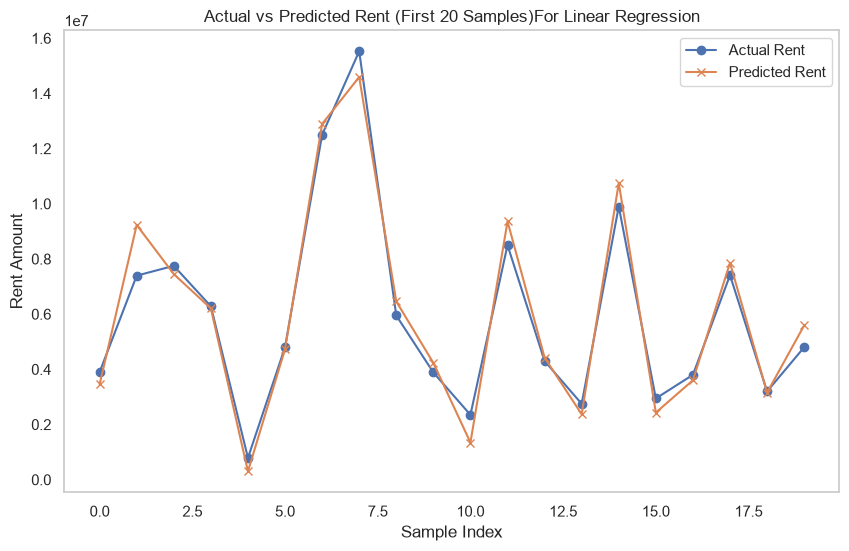

  7%|▋         | 1/14 [00:00<00:03,  3.63it/s]c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.164444e+15, tolerance: 7.938e+12
  model = cd_fast.enet_coordinate_descent(


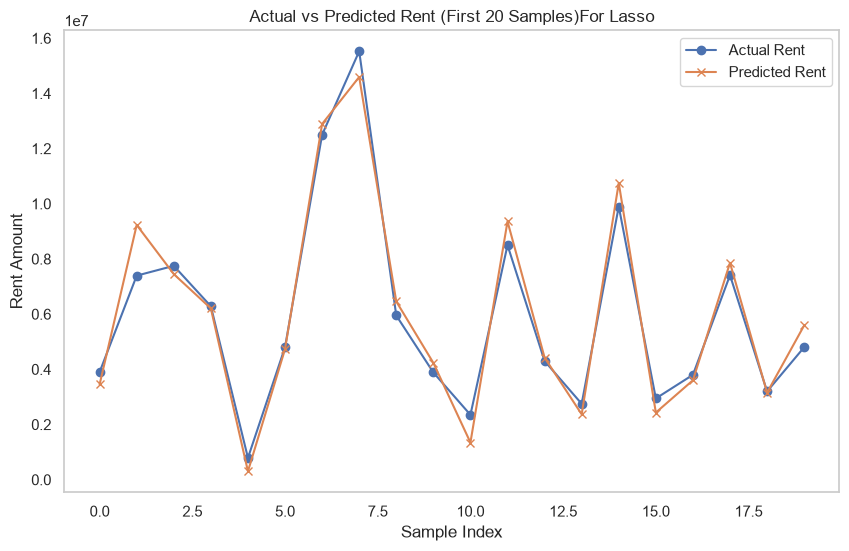

 14%|█▍        | 2/14 [00:00<00:03,  3.39it/s]

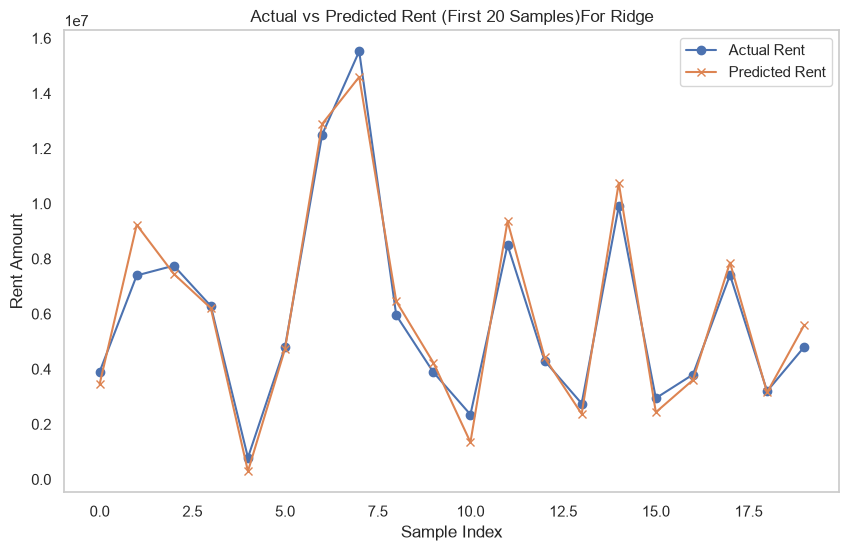

 21%|██▏       | 3/14 [00:00<00:03,  3.59it/s]

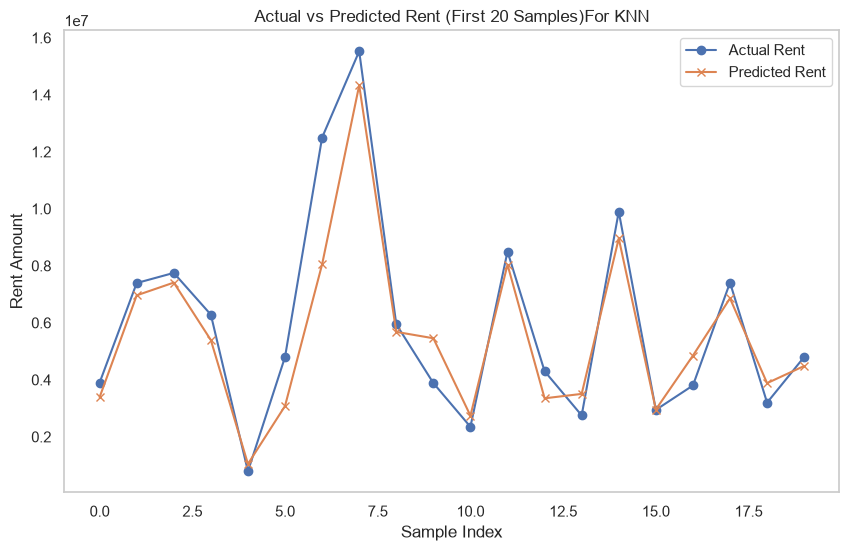

 29%|██▊       | 4/14 [00:01<00:03,  3.32it/s]

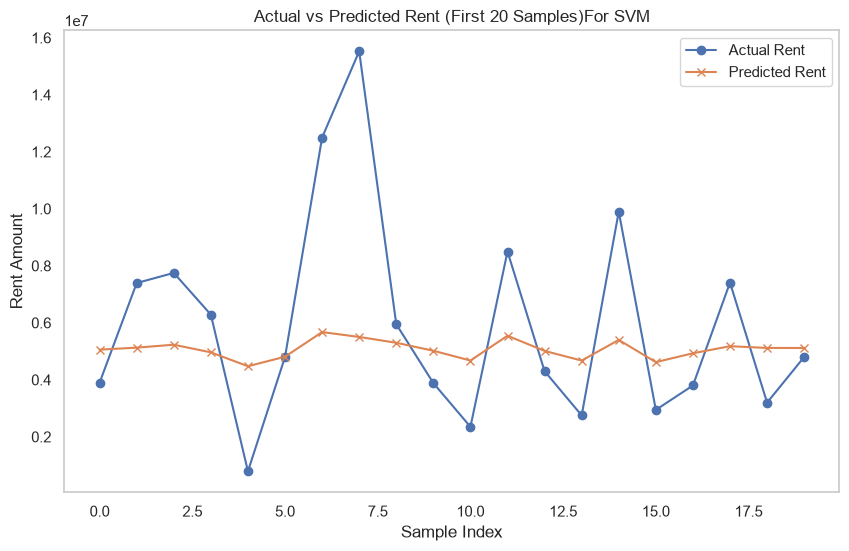

 36%|███▌      | 5/14 [00:02<00:04,  1.95it/s]

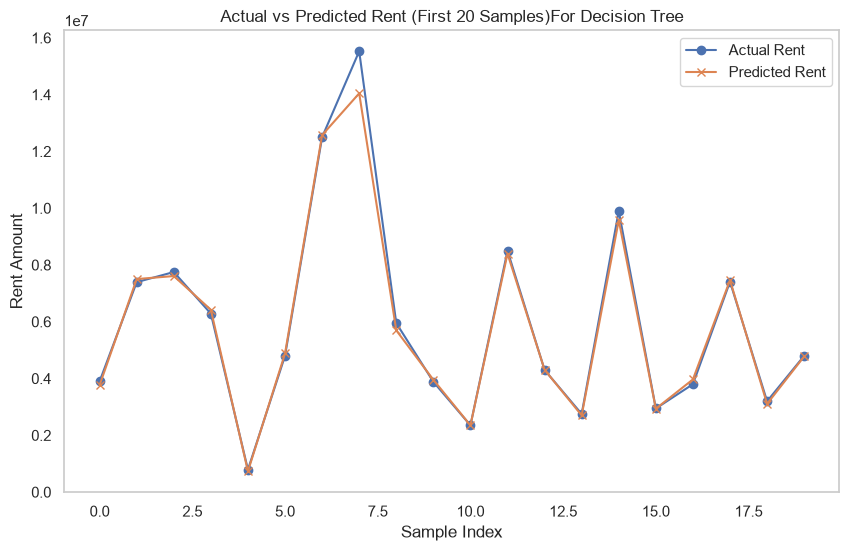

 43%|████▎     | 6/14 [00:02<00:03,  2.36it/s]

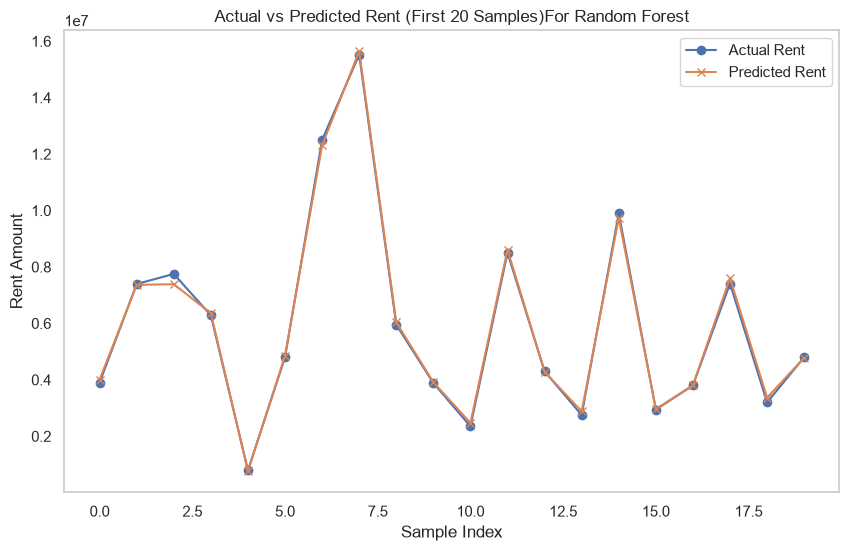

 50%|█████     | 7/14 [00:03<00:03,  1.88it/s]

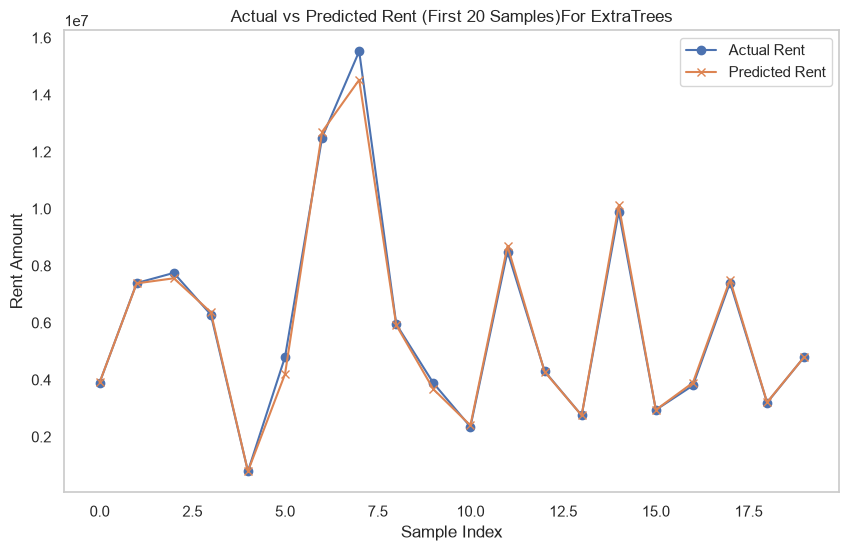

 57%|█████▋    | 8/14 [00:04<00:05,  1.03it/s]

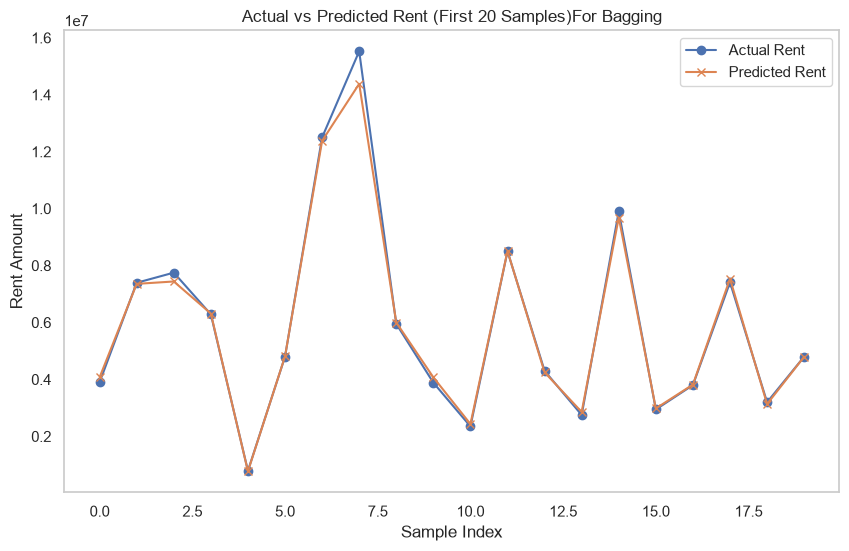

 64%|██████▍   | 9/14 [00:05<00:04,  1.08it/s]

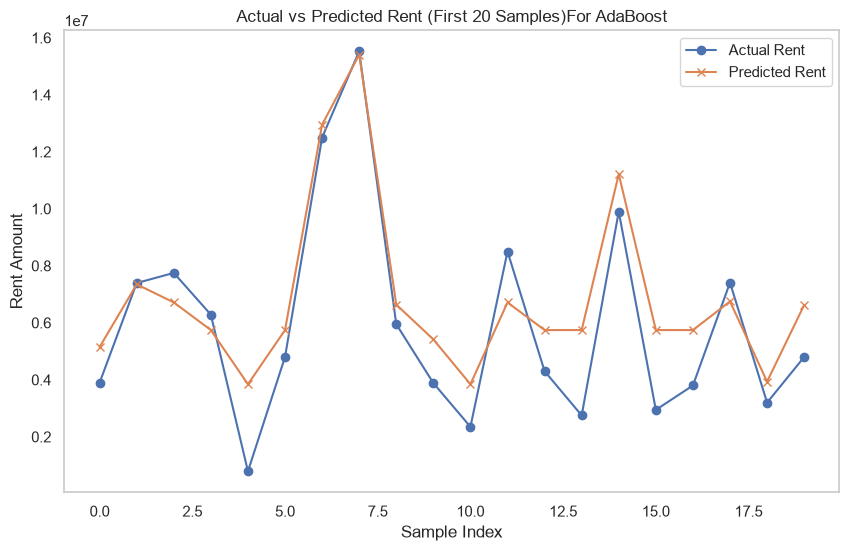

 71%|███████▏  | 10/14 [00:06<00:02,  1.35it/s]

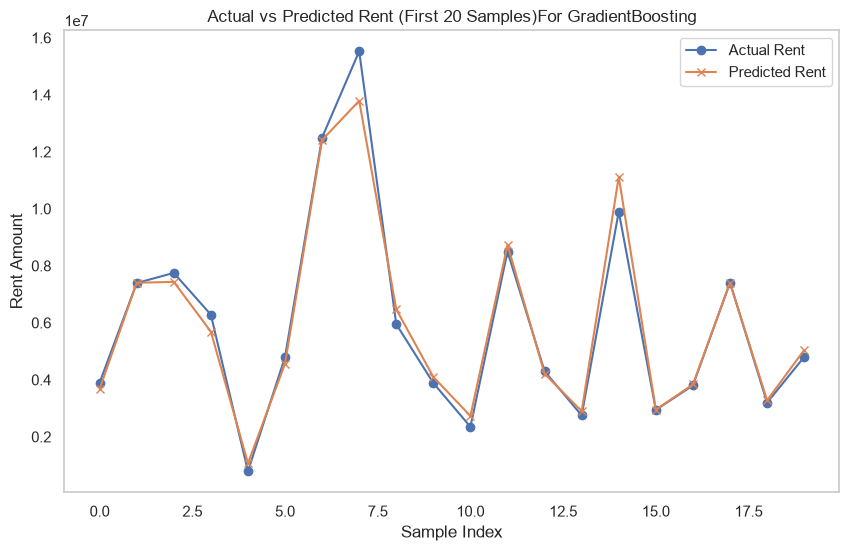

 79%|███████▊  | 11/14 [00:06<00:02,  1.41it/s]

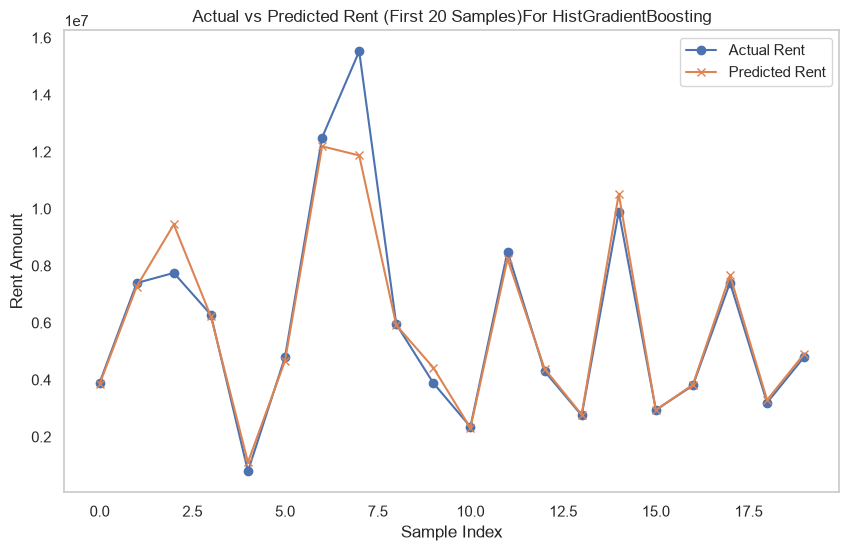

 86%|████████▌ | 12/14 [00:07<00:01,  1.52it/s]

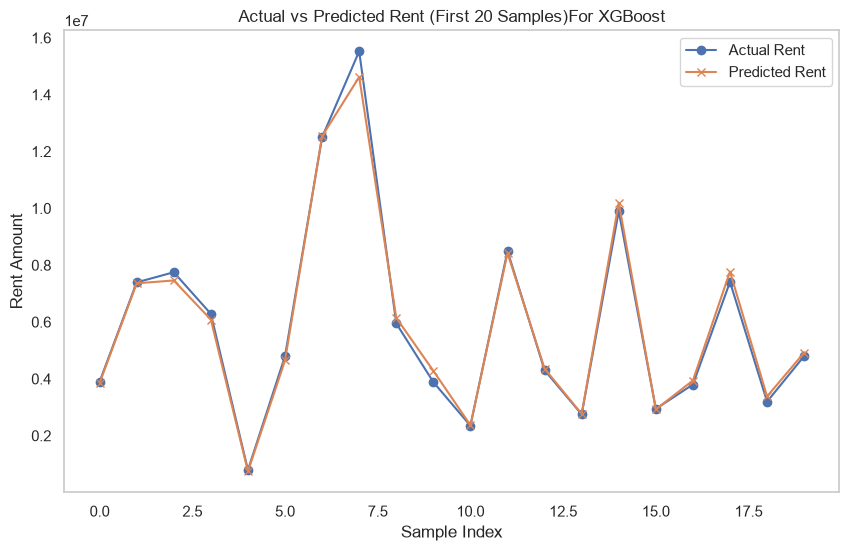

 93%|█████████▎| 13/14 [00:07<00:00,  1.53it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000547 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 525
[LightGBM] [Info] Number of data points in the train set: 3424, number of used features: 27
[LightGBM] [Info] Start training from score 6238463.142815


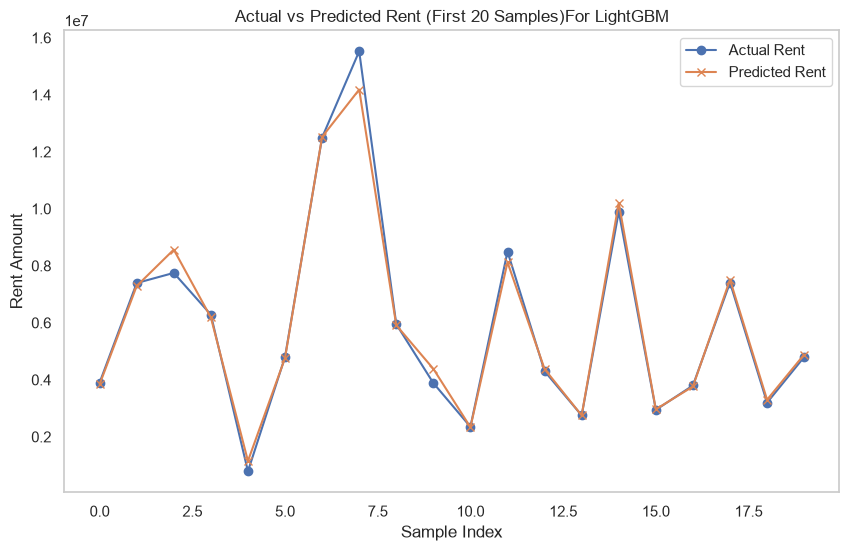

100%|██████████| 14/14 [00:08<00:00,  1.69it/s]


In [ ]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train_df,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train_df, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test_df, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test_df[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [ ]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models using preprocessed data
model1.fit(X_train_df, y_train)
model2.fit(X_train_df, y_train)
model3.fit(X_train_df, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train_df, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model1, X_test_df, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train_df, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model2, X_test_df, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train_df, y_train)
MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(model3, X_test_df, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [ ]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    #('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)

# Fit using preprocessed dataframes
stacking_regressor.fit(X_train_df, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train_df, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test_df, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [ ]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [ ]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,1.394095e+05,2.442793e+05,9.551666e+10,3.228849e+11,3.090577e+05,5.682296e+05,0.995880,0.979547
Random Forest,1.846954e+05,2.292495e+05,6.612686e+11,3.928168e+11,8.131842e+05,6.267510e+05,0.971476,0.975117
Voting,3.378805e+05,3.511056e+05,1.211157e+12,4.636049e+11,1.100526e+06,6.808854e+05,0.947756,0.970633
Simple Voting,3.378805e+05,3.511056e+05,1.211157e+12,4.636049e+11,1.100526e+06,6.808854e+05,0.947756,0.970633
Weighted Voting,3.910528e+05,3.983462e+05,1.413450e+12,5.747992e+11,1.188886e+06,7.581552e+05,0.939030,0.963590
Bagging,1.794304e+05,2.526964e+05,7.903269e+11,6.376198e+11,8.890033e+05,7.985110e+05,0.965909,0.959611
HistGradientBoosting,3.064485e+05,3.178095e+05,2.162591e+12,6.413350e+11,1.470575e+06,8.008339e+05,0.906715,0.959375
LightGBM,3.020578e+05,3.171557e+05,2.083445e+12,6.559305e+11,1.443414e+06,8.098954e+05,0.910129,0.958451
ExtraTrees,1.323043e+02,2.198353e+05,1.445881e+07,9.563701e+11,3.802474e+03,9.779418e+05,0.999999,0.939420
Stacking,2.211254e+05,3.209082e+05,3.227486e+12,1.144554e+12,1.796520e+06,1.069838e+06,0.860779,0.927499


<Axes: >

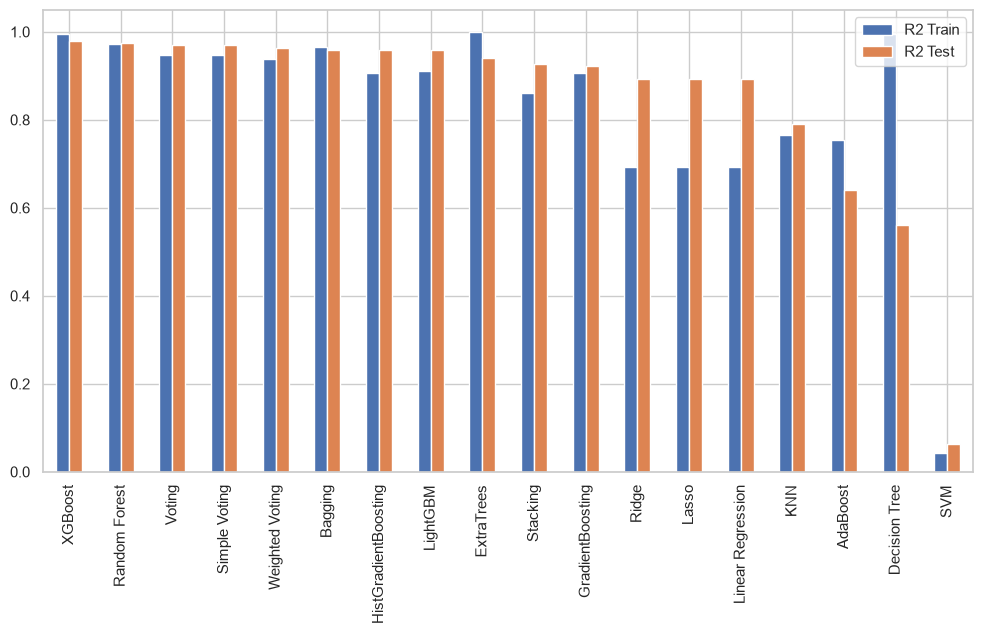

In [ ]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

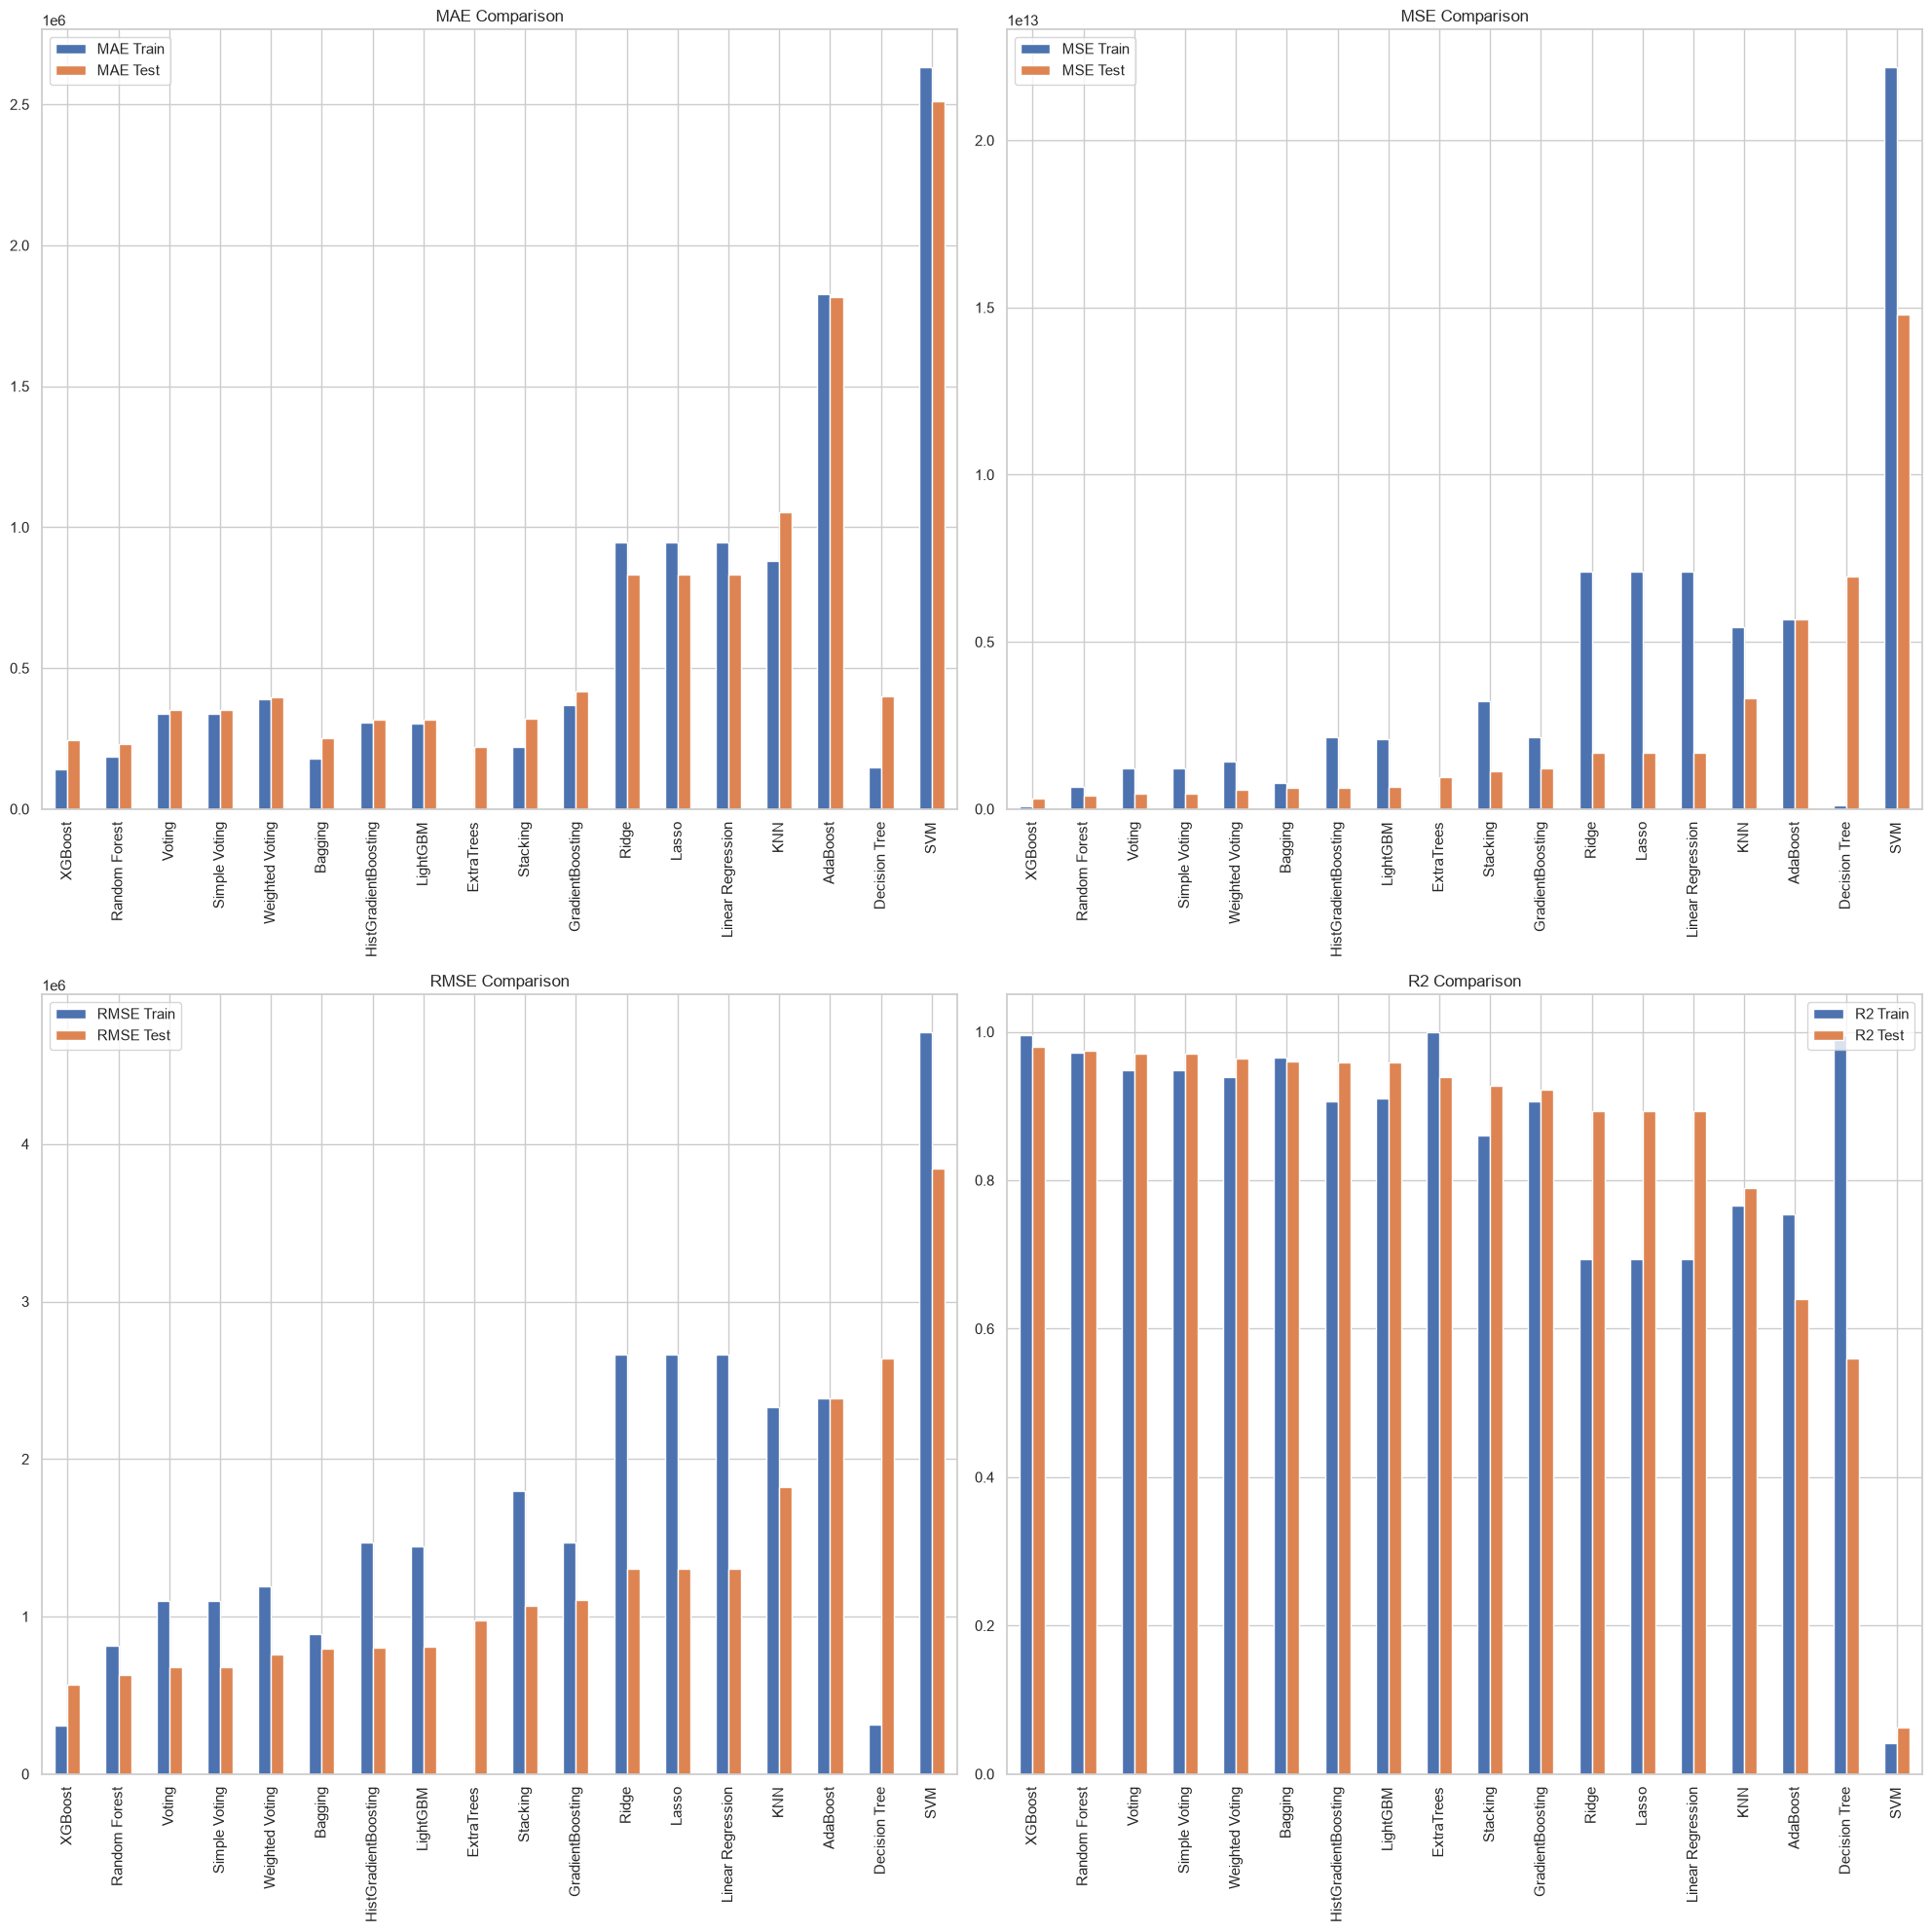

In [ ]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)   
    errors_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q gradio
import gradio as gr
import pandas as pd
import numpy as np

# Retrieve the trained XGBoost model from your models dictionary
xgb_model = models["XGBoost"]

# Get categorical unique categories directly from your dataset for the dropdown options
seller_options = sorted(list(df['seller_type'].dropna().unique()))
view_options = sorted(list(df['view'].dropna().unique()))
payment_options = sorted(list(df['payment_method'].dropna().unique()))
finishing_options = sorted(list(df['finishing_type'].dropna().unique()))

def predict_apartment_price(area_sqm, rooms, bathrooms, floor_level, year_built, price_per_sqm, seller_type, view, payment_method, finishing_type):
    # 1. Create a single-row DataFrame matching the exact raw input structure used in training
    input_data = pd.DataFrame([{
        "area_sqm": float(area_sqm),
        "rooms": float(rooms),
        "bathrooms": float(bathrooms),
        "floor_level": float(floor_level),
        "year_built": int(year_built),
        "seller_type": seller_type,
        "view": view,
        "payment_method": payment_method,
        "finishing_type": finishing_type
    }])
    
    # 2. Preprocess the raw input using the already-fitted pipeline
    processed_input = preprocessing_pipeline.transform(input_data)
    
    # 3. Predict the price using the trained XGBoost model
    prediction = xgb_model.predict(processed_input)[0]
    
    # Return formatted price
    return f"{prediction:,.2f} EGP"

# Setup Gradio Interface
inputs = [
    gr.Number(value=120.0, label="Area (sqm)"),
    gr.Slider(minimum=1, maximum=15, step=1, value=3, label="Number of Rooms"),
    gr.Slider(minimum=1, maximum=10, step=1, value=2, label="Number of Bathrooms"),
    gr.Number(value=3.0, label="Floor Level"),
    gr.Number(value=2024, label="Year Built"),
    gr.Dropdown(choices=seller_options, value=seller_options[0], label="Seller Type"),
    gr.Dropdown(choices=view_options, value=view_options[0], label="View"),
    gr.Dropdown(choices=payment_options, value=payment_options[0], label="Payment Method"),
    gr.Dropdown(choices=finishing_options, value=finishing_options[0], label="Finishing Type")
]

output = gr.Textbox(label="Predicted Apartment Price")

app = gr.Interface(
    fn=predict_apartment_price,
    inputs=inputs,
    outputs=output,
    title="Apartment Price Prediction (XGBoost)",
    description="Enter the details of the apartment to predict its price using the trained XGBoost model."
)

# Launch application
app.launch(share=True)


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\abdoa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.
